# 6주차 · 워크북 0 — 감성데이터 수집하기 — 완성본

**인공지능과 데이터 활용 · 고객 리뷰 데이터의 가공 및 분석**

분석은 데이터를 **어디서, 어떤 조건으로, 어떻게 모았는지**를 기록하는 데서 시작합니다.
이 워크북에서는 공개된 **네이버 쇼핑 실제 상품 후기 20만 건**(Public Domain)을 직접 내려받아 품질을 점검하고,
개인정보로 보이는 문장을 거른 뒤, 별점별로 고르게 **300건을 뽑아 수업용 데이터**를 만듭니다.

```
원자료 확인(출처·라이선스) → 다운로드 → 구조·품질 점검 → 정제·개인정보 필터 → 층화 무작위 추출 → 수집 기록 저장
```

| 단계 | 산출물 |
|---|---|
| 0-1 ~ 0-3 수집·점검 | 원자료 20만 행, 품질 점검표 |
| 0-4 정제 | 단계별 건수표 (깔때기 그림) |
| 0-5 추출 | `week06_my_collected_300.csv` — 수업 데이터와 **MD5가 같아야 성공** |
| 0-6 기록 | `week06_collection_record.json` |

**실행:** `런타임 → 모두 실행`. 실습본은 `TODO`의 `...`을 채운 뒤 실행하고, 각 단계 아래 **기대값**과 비교하세요.

## 감성데이터를 얻는 5가지 경로
| 방법 | 예 | 먼저 확인할 것 | 이번 수업 |
|---|---|---|---|
| A. 공개 말뭉치 다운로드 | bab2min 네이버쇼핑 리뷰, NSMC 영화리뷰 | 라이선스, 수집 시기, 라벨을 붙인 방법 | ✅ |
| B. 공공·연구 데이터 포털 | AI Hub 감성 데이터 | 회원가입·이용신청, 재배포 조건 | 소개 |
| C. 직접 설문·라벨링 | Google Forms → Sheets | 동의, 개인정보 제외, 응답자 편향 | 선택 실습(0-7) |
| D. 자사 데이터·공식 API | 내 쇼핑몰 리뷰 DB, 판매자 API | 이용약관, 접근 권한 | 소개 |
| E. 웹 크롤링 | 상품 페이지 후기 | 약관·robots.txt·저작권·개인정보 | ❌ 하지 않음 |

**라벨은 어디서 오나?** 이 데이터의 긍정/부정은 사람이 문장을 읽고 붙인 것이 아니라 **작성자가 준 별점**(4~5점=긍정, 1~2점=부정)에서 왔습니다.
편리하지만 별점과 본문이 어긋나는 경우가 있다는 점을 0-8에서 직접 확인합니다.

## 0. 실행 환경 준비

In [1]:
!pip -q install koreanize-matplotlib      # 그래프 한글 표시 (처음 한 번, 약 10초)

In [2]:
import os, json, re
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib              # import만 하면 그래프 한글이 깨지지 않음
plt.rcParams["axes.unicode_minus"] = False
os.makedirs("figures", exist_ok=True)   # 그림 저장 폴더

### 데이터 위치 선택 (`DATA_SOURCE`)
| 값 | 동작 | 쓰는 상황 |
|---|---|---|
| `"auto"` (기본) | GitHub 수업 저장소에서 읽고, 안 되면 **내 Google Drive**에서 `week06_MANIFEST.csv`가 있는 폴더를 자동으로 찾음 | 평소 |
| `"drive"` | 내 Drive에 미리 저장한 데이터만 사용 (처음 한 번 Drive 접근 허용) | 수업 중 GitHub가 불안정할 때 |
| `"upload"` | 내려받아 둔 파일을 직접 업로드 | Drive 연결이 어려울 때 |

어느 경로든 노트북이 파일마다 **MD5(파일 지문)** 를 확인해 `정상` 여부를 표로 보여 줍니다. 같은 파일이면 기대값도 똑같이 나옵니다.

In [3]:
# ── 데이터 위치 선택 ─────────────────────────────────────────
DATA_SOURCE = "auto"          # "auto" | "drive" | "upload" | "github"

import os, glob, io, gzip, hashlib, urllib.request
import pandas as pd

GITHUB_BASE = "https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week06/data/"
MANIFEST = "week06_MANIFEST.csv"

def _find_in_drive():
    from google.colab import drive
    if not os.path.isdir("/content/drive/MyDrive"):
        drive.mount("/content/drive")
    for depth in range(0, 7):                                   # 내 드라이브 아래 6단계까지 탐색
        hits = sorted(glob.glob("/content/drive/MyDrive/" + "*/" * depth + MANIFEST))
        if hits:
            return os.path.dirname(hits[0]) + "/"
    raise FileNotFoundError("내 Drive에서 week06_MANIFEST.csv 를 찾지 못했습니다.\n"
        "· 공유받은 '강의6주/01_데이터' 폴더를 오른쪽 클릭 → 정리 → '바로가기 추가' → '내 드라이브' 후 다시 실행하세요.")

def _upload():
    from google.colab import files
    os.makedirs("week06_data", exist_ok=True)
    print("01_데이터 폴더에서 내려받은 파일(week06_MANIFEST.csv 포함)을 모두 선택하세요.")
    for name, data in files.upload().items():
        open(os.path.join("week06_data", name), "wb").write(data)
    return "week06_data/"

def resolve_base(source=DATA_SOURCE):
    if source in ("auto", "github"):
        try:
            urllib.request.urlopen(GITHUB_BASE + MANIFEST, timeout=15).read()
            return GITHUB_BASE
        except Exception as e:
            if source == "github":
                raise
            print("GitHub 접속 실패 → Google Drive에서 찾습니다:", type(e).__name__)
            source = "drive"
    if source == "drive":
        return _find_in_drive()
    if source == "upload":
        return _upload()
    if os.path.isdir(source):                                   # 폴더 경로를 직접 적은 경우
        return source.rstrip("/") + "/"
    raise ValueError("DATA_SOURCE 값을 확인하세요: " + str(source))

def read_bytes(name):
    if BASE.startswith("http"):
        return urllib.request.urlopen(BASE + name, timeout=120).read()
    return open(BASE + name, "rb").read()

BASE = resolve_base()
manifest = pd.read_csv(io.BytesIO(read_bytes(MANIFEST)), encoding="utf-8-sig")
print("데이터 위치:", BASE)
manifest[["file", "bytes", "rows", "note"]]

데이터 위치: https://raw.githubusercontent.com/itlects/2026-2_ai-data/main/Week06/data/


,file,bytes,rows,note
0,week06_reviews_300.csv,36901,300,수업용 표본 (워크북 1~4 입력)
1,naver_shopping.txt.gz,7699143,200000,"원자료 미러, 압축 해제 MD5=cd029e474cd8724af42244cc1207..."


In [4]:
# 파일 지문(MD5) 확인: 수업 저장소 원본과 똑같은 파일인지 검사
def check_file(name):
    data = read_bytes(name)
    expected = manifest.set_index("file").loc[name, "md5"]
    ok = hashlib.md5(data).hexdigest() == expected
    print(f"{name:28s} {len(data):>10,} bytes  →  {'정상(MD5 일치)' if ok else '⚠ 다른 파일! 강의자에게 알리세요'}")
    return data

---
## 0-1. 원자료 확인 — 출처와 라이선스
배포처: **bab2min/corpus** → <https://github.com/bab2min/corpus/tree/master/sentiment>

README에서 확인한 내용 (2026-10-15)
- 출처: 네이버 쇼핑 상품별 후기, 수집 2020.06~07, **20만 건**
- 형식: 탭(\t) 구분, 헤더 없음 — 1열 별점(1~5), 2열 후기
- 별점 **3점은 배포자가 제외**, 긍정(4~5)·부정(1~2) 약 1:1
- 라이선스: **Public Domain**

> 직접 해 보기: 위 링크를 열어 README의 데이터 분포 표를 찾아 아래 결과와 비교하세요.

## 0-2. 다운로드 — 원 배포처에서 직접 받기

In [5]:
SOURCE_URL = "https://raw.githubusercontent.com/bab2min/corpus/master/sentiment/naver_shopping.txt"

try:
    raw_bytes = urllib.request.urlopen(SOURCE_URL, timeout=120).read()
    got_from = "원 배포처(bab2min)"
except Exception as e:                       # 원 배포처 접속이 안 되면 수업 저장소/Drive 미러 사용
    print("원 배포처 접속 실패:", type(e).__name__, "→ 수업 미러 사용")
    raw_bytes = gzip.decompress(check_file("naver_shopping.txt.gz"))
    got_from = "수업 미러"

RAW_MD5 = hashlib.md5(raw_bytes).hexdigest()
print("받은 곳:", got_from, "| 크기:", f"{len(raw_bytes):,} bytes", "| MD5:", RAW_MD5)
print("수업 기준 MD5와 같은가?", RAW_MD5 == "cd029e474cd8724af42244cc1207799d")
print(raw_bytes[:300].decode("utf-8"))      # 원문 앞부분을 그대로 보기

받은 곳: 원 배포처(bab2min) | 크기: 20,623,547 bytes | MD5: cd029e474cd8724af42244cc1207799d
수업 기준 MD5와 같은가? True
5	배공빠르고 굿
2	택배가 엉망이네용 저희집 밑에층에 말도없이 놔두고가고
5	아주좋아요 바지 정말 좋아서2개 더 구매했어요 이가격에 대박입니다. 바느질이 조금 엉성하긴 하지만 편하고 가성비 최고예요.
2	선물용으로 빨리 


**기대값:** 크기 `20,623,547 bytes`, MD5 일치 `True`. 첫 줄 `5\t배공빠르고 굿`

**관찰:** 글자 사이의 `\t`가 열 구분자입니다. 헤더(열 이름) 줄이 없다는 점도 확인하세요.

## 0-3. 표로 읽고 구조·품질 점검

In [6]:
# TODO 1: 탭 구분·헤더 없는 파일을 읽으세요.  sep="\t", header=None, names=["rating","review_text"]
raw = pd.read_csv(io.BytesIO(raw_bytes), sep="\t", header=None, names=["rating", "review_text"],
                  quoting=3, dtype={"rating": "int64", "review_text": "string"})
raw.insert(0, "src_line", range(1, len(raw) + 1))      # 원자료 몇 번째 줄인지 기록(출처 추적)
print("행, 열:", raw.shape)
raw.head()

행, 열: (200000, 3)


,src_line,rating,review_text
0,1,5,배공빠르고 굿
1,2,2,택배가 엉망이네용 저희집 밑에층에 말도없이 놔두고가고
2,3,5,아주좋아요 바지 정말 좋아서2개 더 구매했어요 이가격에 대박입니다. 바느질이 조금 ...
3,4,2,선물용으로 빨리 받아서 전달했어야 하는 상품이었는데 머그컵만 와서 당황했습니다. 전...
4,5,5,민트색상 예뻐요. 옆 손잡이는 거는 용도로도 사용되네요 ㅎㅎ


In [7]:
quality = pd.Series({
    "전체 행": len(raw),
    "후기 결측": raw["review_text"].isna().sum(),
    "같은 문장이 또 나온 행(duplicated)": raw["review_text"].str.strip().duplicated().sum(),
    "전화번호·이메일·URL로 보이는 행": raw["review_text"].str.contains(
        r"(?:\d{2,4}[-.\s]?\d{3,4}[-.\s]?\d{4}|@|https?://|www\.|\.com)", regex=True).sum(),
    "10자 미만": (raw["review_text"].str.len() < 10).sum(),
    "150자 초과": (raw["review_text"].str.len() > 150).sum(),
}, name="건수")
display(quality.to_frame())
display(raw["rating"].value_counts().sort_index().rename("건수").to_frame().T)

,건수
전체 행,200000
후기 결측,0
같은 문장이 또 나온 행(duplicated),92
전화번호·이메일·URL로 보이는 행,122
10자 미만,4278
150자 초과,0


rating,1,2,4,5
건수,36048,63989,18786,81177


**기대값:** 전체 200,000 · 결측 0 · 중복 92 · 개인정보 의심 122 · 10자 미만 4,278 · 150자 초과 0 · 별점 1: 36,048 / 2: 63,989 / 4: 18,786 / 5: 81,177 (3점 없음)

**생각해 보기:** 실제 쇼핑몰에서는 5점이 대부분입니다. 이 데이터가 긍·부정 1:1인 이유는? (→ 배포자가 실험용으로 맞춰 뽑음)

## 0-4. 정제 — 규칙을 정하고, 단계마다 몇 건이 빠지는지 기록
| 순서 | 규칙 | 이유 |
|---|---|---|
| ① | 앞뒤 공백 제거, 연속 공백 → 1칸 | 같은 문장이 공백 때문에 다르게 보이지 않게 |
| ② | 같은 문장이 2번 이상이면 **모두 제외** (`keep=False`) | 복사·도배 후기 제거 |
| ③ | 전화번호·이메일·URL 형태 제외 | 개인정보·광고 |
| ④ | 10~150자만 사용 | 너무 짧으면 판단 불가, 너무 길면 수업용으로 읽기 어려움 |

In [8]:
PII_PATTERN = r"(?:\d{2,4}[-.\s]?\d{3,4}[-.\s]?\d{4}|@|https?://|www\.|\.com)"
steps = [("원자료", len(raw))]

c = raw.dropna(subset=["review_text"]).copy()
c["review_text"] = c["review_text"].str.strip().str.replace(r"\s+", " ", regex=True)   # ①
# TODO 2: 같은 문장이 여러 번 나오면 모두 제외하세요.  힌트: drop_duplicates(subset=[...], keep=False)
c = c.drop_duplicates(subset=["review_text"], keep=False);              steps.append(("② 중복 문장 제외", len(c)))
# TODO 3: 개인정보 패턴이 '들어있지 않은' 행만 남기세요.  힌트: ~c["review_text"].str.contains(PII_PATTERN, regex=True)
c = c[~c["review_text"].str.contains(PII_PATTERN, regex=True)];        steps.append(("③ 개인정보 의심 제외", len(c)))
c = c[c["review_text"].str.len().between(10, 150)];                     steps.append(("④ 길이 10~150자", len(c)))

funnel = pd.DataFrame(steps, columns=["단계", "남은 행"])
funnel["제외"] = (-funnel["남은 행"].diff()).fillna(0).astype(int)
display(funnel)

,단계,남은 행,제외
0,원자료,200000,0
1,② 중복 문장 제외,199816,184
2,③ 개인정보 의심 제외,199694,122
3,④ 길이 10~150자,195423,4271


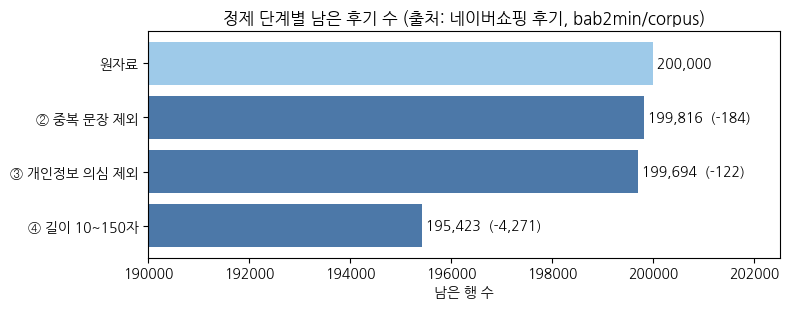

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(funnel["단계"][::-1], funnel["남은 행"][::-1], color=["#4C78A8"] * 3 + ["#9ecae9"])
for y, (v, d) in enumerate(zip(funnel["남은 행"][::-1], funnel["제외"][::-1])):
    ax.text(v, y, f" {v:,}" + (f"  (-{d:,})" if d else ""), va="center")
ax.set_xlim(190000, 202500); ax.set_xlabel("남은 행 수")
ax.set_title("정제 단계별 남은 후기 수 (출처: 네이버쇼핑 후기, bab2min/corpus)")
plt.tight_layout(); plt.savefig("figures/fig_w0_funnel.png", dpi=120); plt.show()

**기대값:** ② 199,816 (−184) → ③ 199,694 (−122) → ④ **195,423** (−4,271)

## 0-5. 층화 무작위 추출 — 별점별 75건씩, 300건
전체 20만 건을 다 읽을 수는 없으니 **표본**을 뽑습니다. 그냥 300건을 뽑으면 5점이 많이 나오므로,
별점(1·2·4·5)마다 같은 수를 뽑는 **층화 추출**을 합니다. `random_state=2026`을 쓰면 누가 실행해도 같은 300건이 나옵니다.

In [10]:
# TODO 4: 별점별로 75건씩 무작위로 뽑으세요.  힌트: c.groupby("rating").sample(n=75, random_state=2026)
s = c.groupby("rating").sample(n=75, random_state=2026)
s = s.sample(frac=1, random_state=2026).reset_index(drop=True)          # 순서 섞기
s.insert(0, "review_id", [f"R{i:03d}" for i in range(1, len(s) + 1)])
# TODO 5: 별점 4~5점은 "긍정", 1~2점은 "부정"으로 참고 라벨을 만드세요.
s["rating_label"] = s["rating"].map(lambda r: "긍정" if r >= 4 else "부정")
s["review_text"] = s["review_text"].astype(str)
sample = s[["review_id", "src_line", "rating", "rating_label", "review_text"]]
display(sample.head(8))
print(sample["rating"].value_counts().sort_index().to_dict(), sample["rating_label"].value_counts().to_dict())

,review_id,src_line,rating,rating_label,review_text
0,R001,192873,4,긍정,오리상태도 좋고 밋도 있어여 다만 포장에 기름이 좀 묻어 있어서 별하나 뺐어요
1,R002,81447,4,긍정,세팅력이 우수합니다
2,R003,94168,5,긍정,"화장하기 편하고, 피부표현이 매끄럽게 되용"
3,R004,72762,2,부정,뚜껑끼우는게 너무 힘들어서 손이 많이 아픕니다. 통이 찌그러져오지않았다면 그렇게 힘...
4,R005,26587,2,부정,일단 패드장착이 안되어 왔구요~ 패드부분만 볼록하게 튀어나와서 너무 티가나요~
5,R006,162857,5,긍정,일단 강추 입니다 세련 되었고 싼티 나지 않습니다 만족스럽스니다
6,R007,116410,5,긍정,잘받았어요. 잘쓸깨요
7,R008,8605,5,긍정,대구지역~~~~아직 제품과 만나지 못했네요 친절하게도 집안에 배송을 해주셔서~~~~~


{1: 75, 2: 75, 4: 75, 5: 75} {'긍정': 150, '부정': 150}


In [11]:
OUT = "week06_my_collected_300.csv"
sample.to_csv(OUT, index=False, encoding="utf-8-sig", lineterminator="\n")
mine = hashlib.md5(open(OUT, "rb").read()).hexdigest()
class_md5 = manifest.set_index("file").loc["week06_reviews_300.csv", "md5"]
print("내가 만든 파일 MD5 :", mine)
print("수업 데이터 MD5    :", class_md5)
print("→", "✅ 수업 데이터와 똑같이 재현했습니다!" if mine == class_md5 else "❌ 다릅니다. 정제 규칙·시드를 확인하세요.")

내가 만든 파일 MD5 : 826290503dfc1ab898089886d3225ba0
수업 데이터 MD5    : 826290503dfc1ab898089886d3225ba0
→ ✅ 수업 데이터와 똑같이 재현했습니다!


**기대값:** 첫 행 `R001 · 별점 4 · 오리상태도 좋고 밋도 있어여…` · 별점별 75건 · 긍정 150 / 부정 150 · **MD5 일치 ✅**

> 이것이 **재현 가능성**입니다. 출처·규칙·시드를 기록하면 다른 사람이 같은 데이터를 다시 만들 수 있습니다.

## 0-6. 수집 기록 남기기 (데이터의 이력서)

In [12]:
record = {
    "dataset": "네이버 쇼핑 상품 후기 감성 말뭉치 (naver_shopping.txt)",
    "source_url": SOURCE_URL, "got_from": got_from,
    "license": "Public Domain (bab2min/corpus README, 2026-10-15 확인)",
    "original_period": "2020.06~2020.07 (배포자 수집)",
    "collected_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "raw_md5": RAW_MD5, "raw_rows": int(len(raw)),
    "cleaning_steps": {k: int(v) for k, v in steps},
    "sampling": "별점 1·2·4·5 각 75건, groupby.sample(random_state=2026)",
    "label_rule": "별점 4~5=긍정, 1~2=부정 (사람이 본문을 읽고 붙인 라벨 아님)",
    "sample_rows": int(len(sample)), "sample_md5": mine,
    "limitations": ["중립(3점) 없음", "별점과 본문이 어긋나는 후기 존재", "2020년 네이버쇼핑 한정"],
}
json.dump(record, open("week06_collection_record.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print(json.dumps(record, ensure_ascii=False, indent=2))

{
  "dataset": "네이버 쇼핑 상품 후기 감성 말뭉치 (naver_shopping.txt)",
  "source_url": "https://raw.githubusercontent.com/bab2min/corpus/master/sentiment/naver_shopping.txt",
  "got_from": "원 배포처(bab2min)",
  "license": "Public Domain (bab2min/corpus README, 2026-10-15 확인)",
  "original_period": "2020.06~2020.07 (배포자 수집)",
  "collected_at_utc": "2026-10-14T23:06:04+00:00",
  "raw_md5": "cd029e474cd8724af42244cc1207799d",
  "raw_rows": 200000,
  "cleaning_steps": {
    "원자료": 200000,
    "② 중복 문장 제외": 199816,
    "③ 개인정보 의심 제외": 199694,
    "④ 길이 10~150자": 195423
  },
  "sampling": "별점 1·2·4·5 각 75건, groupby.sample(random_state=2026)",
  "label_rule": "별점 4~5=긍정, 1~2=부정 (사람이 본문을 읽고 붙인 라벨 아님)",
  "sample_rows": 300,
  "sample_md5": "826290503dfc1ab898089886d3225ba0",
  "limitations": [
    "중립(3점) 없음",
    "별점과 본문이 어긋나는 후기 존재",
    "2020년 네이버쇼핑 한정"
  ]
}


## 0-7. (선택) 직접 수집 — 설문으로 내 감성데이터 만들기
1. Google Forms로 질문 2개를 만든다: **① 최근 산 물건의 후기 한두 문장 ② 별점(1~5)**. 이름·연락처는 묻지 않는다.
2. 응답 탭 → **Sheets에 연결** → Sheets에서 `파일 → 공유 → 웹에 게시 → CSV` 링크를 복사한다.
3. 아래 `SHEET_CSV_URL`에 붙여 넣고 실행한다. (비워 두면 건너뜀)

**설문 수집의 한계:** 응답자가 우리 반 학생뿐이라면 결과를 전체 소비자로 일반화할 수 없다(표본 편향).

In [13]:
SHEET_CSV_URL = ""      # 예: "https://docs.google.com/spreadsheets/d/e/....../pub?output=csv"

if SHEET_CSV_URL:
    survey = pd.read_csv(SHEET_CSV_URL)
    survey.columns = ["timestamp", "review_text", "rating"][: len(survey.columns)]
    survey["rating_label"] = survey["rating"].map(lambda r: "긍정" if r >= 4 else ("부정" if r <= 2 else "중립"))
    display(survey.head())
else:
    print("설문 링크가 비어 있어 건너뜁니다.")

설문 링크가 비어 있어 건너뜁니다.


## 0-8. 별점 라벨은 믿을 만한가? — 직접 읽어 보기
아래는 **별점 1~2점인데 칭찬하는 말이 들어 있는** 후기입니다. 작성자가 별점을 잘못 눌렀을까요, 아니면 다른 불만이 있었을까요?

In [14]:
praise = r"추천|최고|만족|좋아요|좋네요|딱이네요|감사"
odd = sample[(sample["rating"] <= 2) & sample["review_text"].str.contains(praise)]
print("별점 1~2점 중 칭찬 표현이 있는 후기:", len(odd), "건")
display(odd[["review_id", "rating", "review_text"]])

별점 1~2점 중 칭찬 표현이 있는 후기: 10 건


,review_id,rating,review_text
8,R009,2,사료 두번째 구입인데 넘잘먹네요 계량컵두 주시고 배송도빠르고 적극 추천합니다
68,R069,1,비커컵은 생각보다 크구여 컵이 불량이라 교체하는데 여러모로 힘들엇네요 톡톡응대가 만...
80,R081,1,유통기한이 너무짧아요~ 도착일기준로 15일도 안되네요~ 아이들 간식용으로 많이 샀는...
84,R085,1,배송도빠르고 원하던디자인에 차량색상이랑도 잘맞고 딱이네요
148,R149,2,제품은 만족하는데 배송기사분에게 불만이 있네요 ㅡㅡ 약속시간 안지키시고 여러모로 불...
169,R170,1,열심히 지울려고 하였지만 잘지워지지않아 크게 만족하지 못한 상태에서 바로 교통사고가...
192,R193,2,냄새가 너무 너무 나네요. 냄새가 너무 심해서 두통이 심하고 속도 안좋네요. 베란다...
250,R251,1,친절한 대응 감사드립니다 좋은제품 많이파세요
293,R294,2,침독크림용도로. 구매했는데 보습력이 일반 크림과 비슷해요 그냥전신쓰기는좋아요
294,R295,1,접착성 완전 안좋아요ㅜ 다시샀네요 다른걸로


**기대값:** 10건 (R009, R069, R081, R085, R149, R170, R193, R251, R294, R295). 이 중 R069·R081·R170·R193·R295는 `만족스럽지않아`, `추천하지 않아요`, `안좋네요`처럼 **부정어가 붙은** 칭찬 단어라 실제로는 불만입니다 → 단어만 찾으면 생기는 함정(워크북 2).

**토의 (제출)**
1. 위 후기 중 3건을 골라 내가 붙일 감성(긍정/부정/중립)과 이유를 쓴다.
2. 별점 라벨로 AI의 "정확도"를 계산하면 어떤 문제가 생길까?
3. 이번 수집에서 **알 수 없는 것** 2가지 (예: 작성자 연령대, 상품 가격대 …)

## 제출물
- [ ] `week06_my_collected_300.csv` (MD5 일치 화면 캡처)
- [ ] `week06_collection_record.json`
- [ ] 정제 깔때기 그림 `figures/fig_w0_funnel.png`
- [ ] 0-8 토의 답안

➡️ 다음: **워크북 1~4 노트북** `Week06_리뷰감성분석_실습.ipynb`